In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the retail dataset
df = pd.read_csv("simulated_retail_business_dataset.csv")

# Display the first five rows
df.head()


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Unit_Cost,Total_Cost,Profit
0,ORD-00001,2024-03-06,North,Home & Kitchen,Mixer Grinder,4,3388.33,0.15,11520.32,2104.64,8418.56,3101.76
1,ORD-00002,2025-07-19,West,Electronics,Keyboard,2,1489.90,0.10,2681.82,853.22,1706.44,975.38
2,ORD-00003,2025-04-23,West,Home & Kitchen,Cookware Set,2,2684.30,0.15,4563.31,1748.20,3496.40,1066.91
3,ORD-00004,2024-11-16,North,Beauty,Perfume,1,1837.97,0.20,1470.38,808.83,808.83,661.55
4,ORD-00005,2024-11-12,North,Clothing,Jeans,2,1533.41,0.10,2760.14,772.38,1544.76,1215.38


In [3]:

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (10000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    10000 non-null  str    
 1   Order_Date  10000 non-null  str    
 2   Region      10000 non-null  str    
 3   Category    10000 non-null  str    
 4   Product     10000 non-null  str    
 5   Quantity    10000 non-null  int64  
 6   Unit_Price  10000 non-null  float64
 7   Discount    10000 non-null  float64
 8   Sales       10000 non-null  float64
 9   Unit_Cost   10000 non-null  float64
 10  Total_Cost  10000 non-null  float64
 11  Profit      10000 non-null  float64
dtypes: float64(6), int64(1), str(5)
memory usage: 937.6 KB

Missing values:
Order_ID      0
Order_Date    0
Region        0
Category      0
Product       0
Quantity      0
Unit_Price    0
Discount      0
Sales         0
Unit_Cost     0
Total_Cost    0
Profit        0
dtype: int64

Duplicate rows: 0


In [4]:

# 1. Convert Order_Date to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

# 2. Check unique order IDs
print("Unique Order IDs:", df["Order_ID"].nunique())
print("Total rows:", len(df))

# 3. Check date range
print("Start date:", df["Order_Date"].min())
print("End date:", df["Order_Date"].max())

# 4. Verify Sales calculation
expected_sales = (
    df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
).round(2)

print(
    "Sales calculation errors:",
    (df["Sales"] - expected_sales).abs().gt(0.011).sum()
)

# 5. Verify Profit calculation
expected_profit = (df["Sales"] - df["Total_Cost"]).round(2)

print(
    "Profit calculation errors:",
    (df["Profit"] - expected_profit).abs().gt(0.011).sum()
)


Unique Order IDs: 10000
Total rows: 10000
Start date: 2024-01-01 00:00:00
End date: 2025-12-31 00:00:00
Sales calculation errors: 0
Profit calculation errors: 0


In [5]:

# Executive-level business KPIs
total_sales = df["Sales"].sum()
total_cost = df["Total_Cost"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100
average_discount = df["Discount"].mean() * 100

print("========== RETAIL BUSINESS KPIs ==========")
print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Product Cost: ₹{total_cost:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Units Sold: {total_units:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Discount: {average_discount:.2f}%")


========== RETAIL BUSINESS KPIs ==========
Total Sales: ₹33,107,710.83
Total Product Cost: ₹20,065,013.90
Total Profit: ₹13,042,696.93
Total Orders: 10,000
Units Sold: 21,097
Average Order Value: ₹3,310.77
Profit Margin: 39.39%
Average Discount: 7.87%


In [6]:

# Analyze performance by product category
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

# Calculate profit margin for each category
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"] * 100
).round(2)

# Sort by sales, highest first
category_analysis = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

category_analysis


,Category,Total_Sales,Total_Profit,Units_Sold,Total_Orders,Profit_Margin_%
2,Electronics,9502182.43,3268187.17,4611,2186,34.39
1,Clothing,8263397.12,3641860.06,5253,2476,44.07
3,Home & Kitchen,7730560.16,2817629.24,4841,2353,36.45
4,Sports,4204172.76,1626679.72,2814,1304,38.69
0,Beauty,3407398.36,1688340.74,3578,1681,49.55


In [7]:

# Analyze performance by region
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"] * 100
).round(2)

# Sort by sales, highest first
region_analysis = region_analysis.sort_values(
    "Total_Sales", ascending=False
)

region_analysis


,Region,Total_Sales,Total_Profit,Units_Sold,Total_Orders,Profit_Margin_%
3,South,7974244.13,3142105.24,5089,2388,39.40
2,North,7632121.01,3022710.03,4853,2299,39.61
4,West,7484695.67,2921112.34,4672,2239,39.03
1,East,5512164.79,2192614.64,3611,1704,39.78
0,Central,4504485.23,1764154.68,2872,1370,39.16


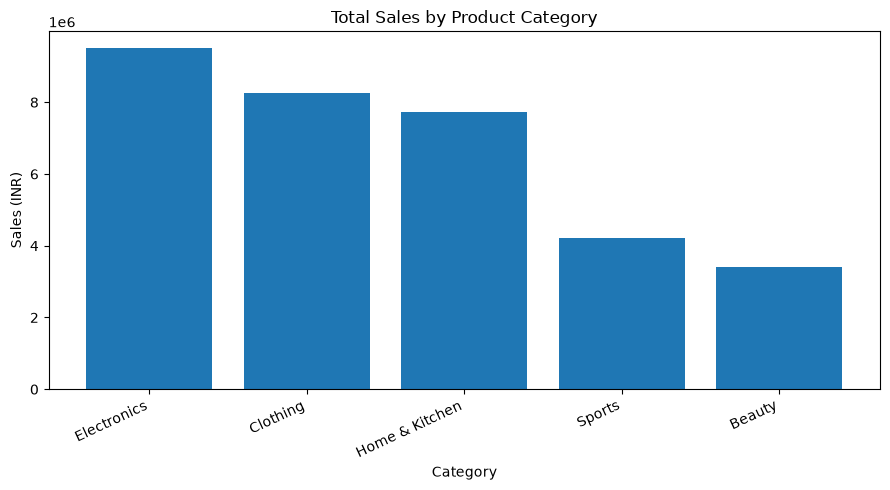

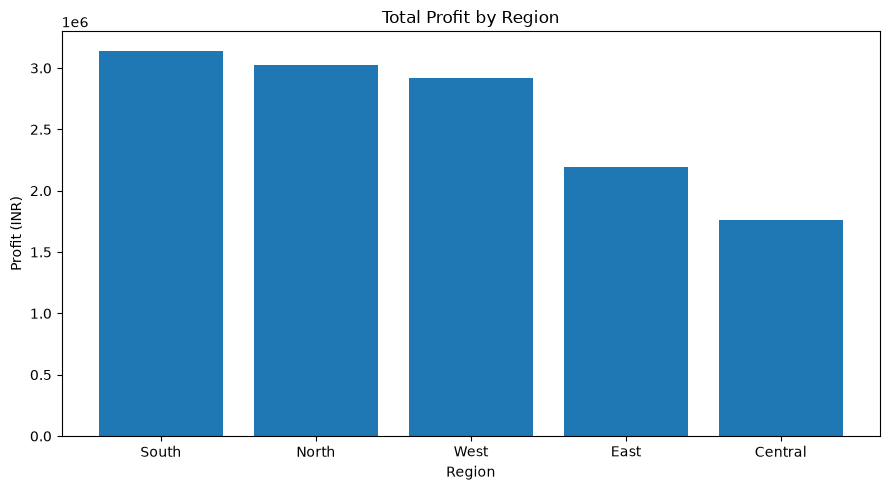

In [8]:

# Chart 1: Sales by category
plt.figure(figsize=(9, 5))
plt.bar(
    category_analysis["Category"],
    category_analysis["Total_Sales"]
)
plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Chart 2: Profit by region
plt.figure(figsize=(9, 5))
plt.bar(
    region_analysis["Region"],
    region_analysis["Total_Profit"]
)
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit (INR)")
plt.tight_layout()
plt.show()


In [9]:

# Create a month column
df["Month"] = df["Order_Date"].dt.to_period("M")

# Calculate monthly performance
monthly_analysis = df.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

# Convert month to timestamp for plotting
monthly_analysis["Month"] = (
    monthly_analysis["Month"].dt.to_timestamp()
)

# Display monthly results
monthly_analysis.head(10)


,Month,Total_Sales,Total_Profit,Total_Orders
0,2024-01-01,1405812.25,554013.45,415
1,2024-02-01,1332374.84,524921.70,380
2,2024-03-01,1435420.07,552784.19,433
3,2024-04-01,1387970.31,555040.62,439
4,2024-05-01,1416651.59,566607.51,436
5,2024-06-01,1336391.24,526456.28,418
6,2024-07-01,1385786.41,546980.44,436
7,2024-08-01,1506585.57,594566.90,448
8,2024-09-01,1211676.53,478183.37,384
9,2024-10-01,1319327.17,514053.46,407


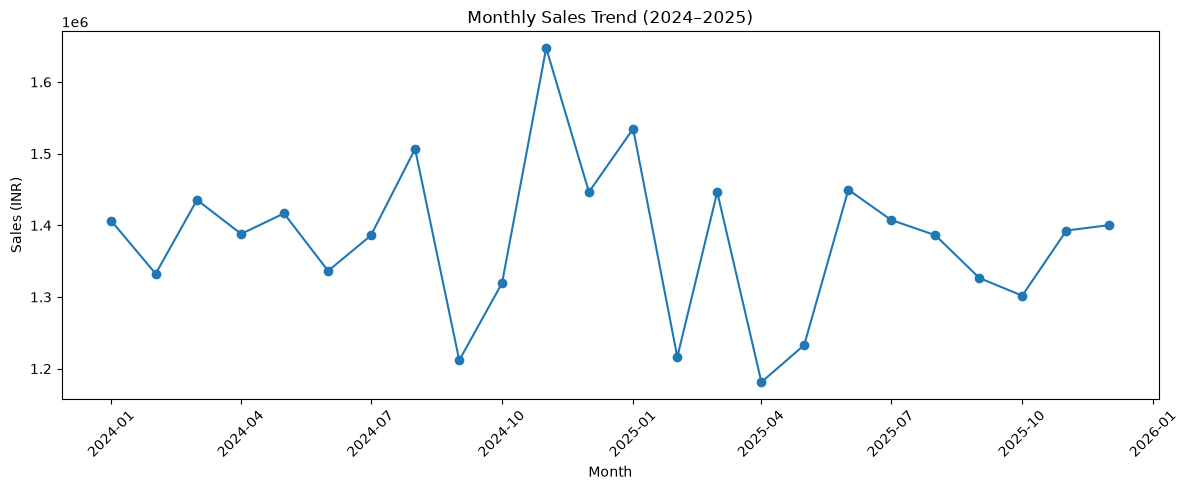

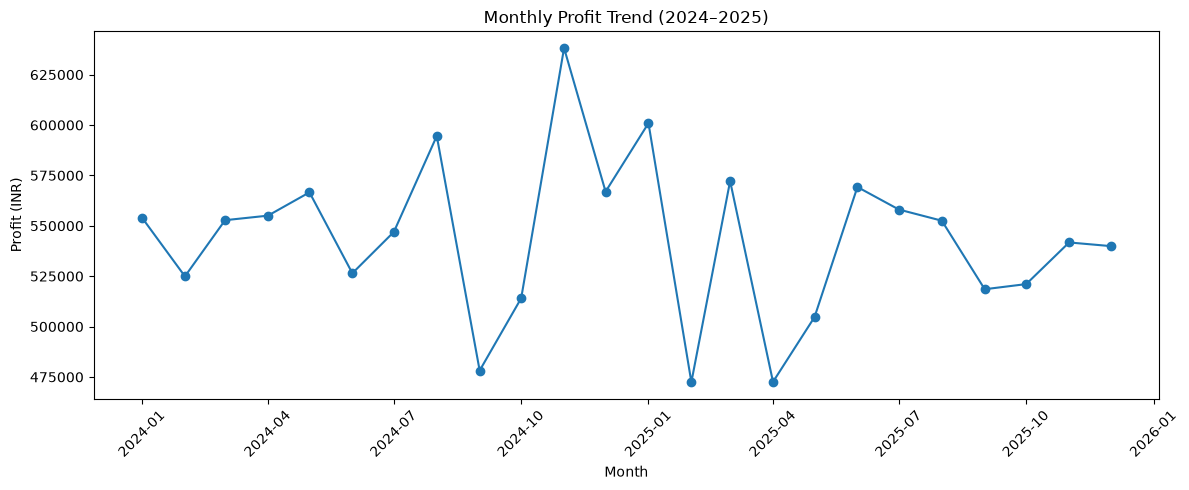

In [10]:

# Monthly sales trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Monthly profit trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Profit"],
    marker="o"
)
plt.title("Monthly Profit Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Profit (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:

df["Year"] = df["Order_Date"].dt.year

yearly_analysis = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

yearly_analysis["Profit_Margin_%"] = (
    yearly_analysis["Total_Profit"]
    / yearly_analysis["Total_Sales"] * 100
).round(2)

yearly_analysis


,Year,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
0,2024,16831771.92,6618773.25,5068,39.32
1,2025,16275938.91,6423923.68,4932,39.47


In [12]:

# Compare monthly sales and profit across years
df["Year"] = df["Order_Date"].dt.year
df["Month_Number"] = df["Order_Date"].dt.month

monthly_comparison = df.groupby(
    ["Year", "Month_Number"]
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order_ID", "nunique")
).reset_index()

# Pivot sales to compare 2024 and 2025
sales_comparison = monthly_comparison.pivot(
    index="Month_Number",
    columns="Year",
    values="Sales"
)

sales_comparison["Sales_Change_%"] = (
    (sales_comparison[2025] - sales_comparison[2024])
    / sales_comparison[2024] * 100
).round(2)

sales_comparison


Year,2024,2025,Sales_Change_%
Month_Number,,,
1,1405812.25,1534780.47,9.17
2,1332374.84,1216242.77,-8.72
3,1435420.07,1446325.99,0.76
4,1387970.31,1181189.00,-14.90
5,1416651.59,1232917.13,-12.97
6,1336391.24,1449648.61,8.47
7,1385786.41,1407489.96,1.57
8,1506585.57,1386189.02,-7.99
9,1211676.53,1326360.25,9.46


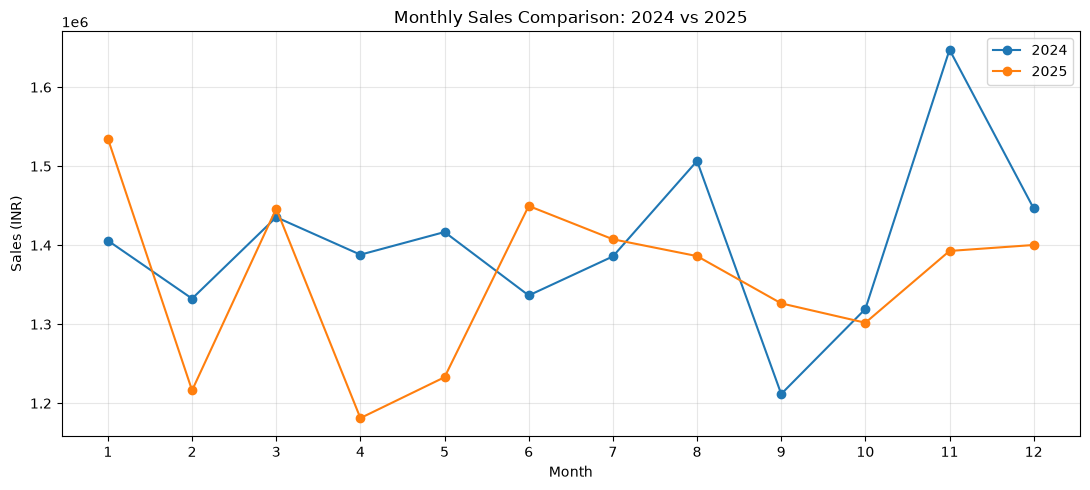

Month with largest decline: 11
Sales change (%): -15.46


In [13]:

plt.figure(figsize=(11, 5))

plt.plot(
    sales_comparison.index,
    sales_comparison[2024],
    marker="o",
    label="2024"
)

plt.plot(
    sales_comparison.index,
    sales_comparison[2025],
    marker="o",
    label="2025"
)

plt.title("Monthly Sales Comparison: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Identify the largest monthly sales decline
print(
    "Month with largest decline:",
    sales_comparison["Sales_Change_%"].idxmin()
)

print(
    "Sales change (%):",
    sales_comparison["Sales_Change_%"].min()
)


In [14]:

# Analyze performance by category and product
product_analysis = df.groupby(
    ["Category", "Product"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order_ID", "nunique")
).reset_index()

product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Profit"]
    / product_analysis["Total_Sales"] * 100
).round(2)

# Top 10 products by sales
top_products = product_analysis.sort_values(
    "Total_Sales", ascending=False
).head(10)

top_products


,Category,Product,Total_Sales,Total_Profit,Units_Sold,Total_Orders,Profit_Margin_%
13,Electronics,Smartwatch,3438640.10,1005884.58,884,420,29.25
17,Home & Kitchen,Mixer Grinder,2916300.82,898067.15,985,468,30.79
5,Clothing,Jacket,2733956.02,1085749.34,1138,541,39.71
16,Home & Kitchen,Cookware Set,2521352.22,870772.35,970,473,34.54
8,Clothing,Sneakers,2280089.22,895570.77,1026,470,39.28
14,Electronics,Speaker,2129631.07,745472.54,892,424,35.00
10,Electronics,Headphones,1622079.60,595878.77,978,457,36.74
6,Clothing,Jeans,1564205.45,766797.11,1063,500,49.02
23,Sports,Running Shoes,1337010.12,475952.32,520,241,35.60
15,Home & Kitchen,Bedsheet,1295315.35,540462.63,1006,509,41.72


In [15]:

# Bottom 10 products by sales
bottom_products = product_analysis.sort_values(
    "Total_Sales", ascending=True
).head(10)

bottom_products


,Category,Product,Total_Sales,Total_Profit,Units_Sold,Total_Orders,Profit_Margin_%
3,Beauty,Shampoo,220930.34,131633.56,685,320,59.58
0,Beauty,Face Cream,384201.78,225222.92,758,348,58.62
19,Home & Kitchen,Water Bottle,429868.97,224794.99,932,454,52.29
22,Sports,Football,436633.46,230364.99,590,272,52.76
24,Sports,Yoga Mat,441788.94,216063.82,538,253,48.91
4,Beauty,Sunscreen,447706.08,252648.39,751,367,56.43
18,Home & Kitchen,Storage Box,567722.80,283532.12,948,449,49.94
9,Clothing,T-Shirt,648671.41,345612.01,1008,480,53.28
21,Sports,Dumbbells,799487.27,307790.67,578,273,38.50
7,Clothing,Kurta,1036475.02,548130.83,1018,485,52.88


In [16]:

# Compare results across discount levels
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Average_Order_Value=("Sales", "mean")
).reset_index()

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"] * 100
).round(2)

discount_analysis["Discount_%"] = (
    discount_analysis["Discount"] * 100
).round(0).astype(int)

discount_analysis


,Discount,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Profit_Margin_%,Discount_%
0,0.00,10057011.32,4427267.55,2757,3647.809692,44.02,0
1,0.05,6837050.64,2818333.42,2030,3368.005241,41.22,5
2,0.10,8864806.15,3355992.26,2718,3261.518083,37.86,10
3,0.15,5109173.03,1758060.20,1706,2994.825926,34.41,15
4,0.20,2239669.69,683043.50,789,2838.618112,30.50,20


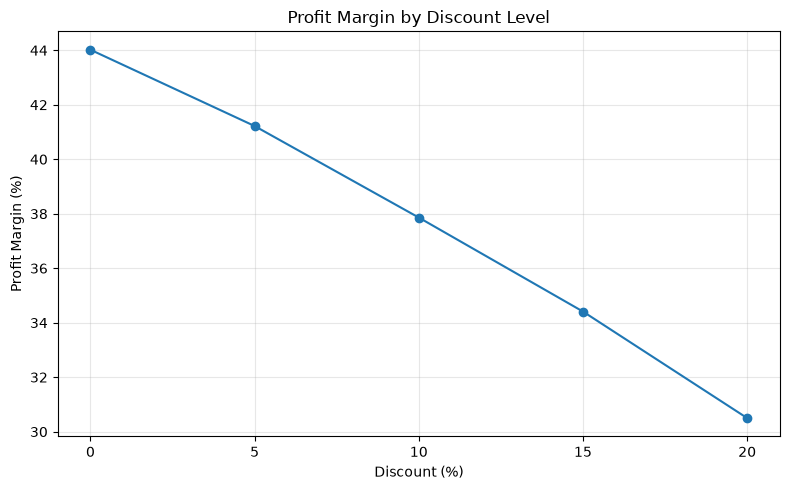

In [17]:

plt.figure(figsize=(8, 5))

plt.plot(
    discount_analysis["Discount_%"],
    discount_analysis["Profit_Margin_%"],
    marker="o"
)

plt.title("Profit Margin by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.xticks(discount_analysis["Discount_%"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Build transparent, hypothetical business scenarios

# Get actual simulated category and product performance
category_kpis = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

product_kpis = df.groupby("Product").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

beauty_sales = category_kpis.loc["Beauty", "Sales"]
beauty_margin = (
    category_kpis.loc["Beauty", "Profit"] / beauty_sales
)

clothing_sales = category_kpis.loc["Clothing", "Sales"]
clothing_margin = (
    category_kpis.loc["Clothing", "Profit"] / clothing_sales
)

smartwatch_sales = product_kpis.loc["Smartwatch", "Sales"]

# Assumptions for illustrative scenarios
scenarios = [
    {
        "Strategy": "Grow Beauty sales by 10%",
        "Profit_Uplift": beauty_sales * 0.10 * beauty_margin,
        "Investment": 75000
    },
    {
        "Strategy": "Grow Clothing sales by 5%",
        "Profit_Uplift": clothing_sales * 0.05 * clothing_margin,
        "Investment": 100000
    },
    {
        "Strategy": "Improve Smartwatch margin by 2 percentage points",
        "Profit_Uplift": smartwatch_sales * 0.02,
        "Investment": 25000
    }
]

roi_df = pd.DataFrame(scenarios)

roi_df["Net_Benefit"] = (
    roi_df["Profit_Uplift"] - roi_df["Investment"]
)

roi_df["ROI_%"] = (
    roi_df["Net_Benefit"] / roi_df["Investment"] * 100
).round(2)

roi_df["Profit_Uplift"] = roi_df["Profit_Uplift"].round(2)
roi_df["Net_Benefit"] = roi_df["Net_Benefit"].round(2)

roi_df


,Strategy,Profit_Uplift,Investment,Net_Benefit,ROI_%
0,Grow Beauty sales by 10%,168834.07,75000,93834.07,125.11
1,Grow Clothing sales by 5%,182093.00,100000,82093.00,82.09
2,Improve Smartwatch margin by 2 percentage points,68772.80,25000,43772.80,175.09


In [19]:

# Executive KPI summary

executive_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Product Cost",
        "Total Profit Before Overheads",
        "Total Orders",
        "Units Sold",
        "Overall Profit Margin",
        "Average Order Value",
        "Highest-Sales Category",
        "Highest-Profit Category",
        "Highest-Margin Category",
        "Highest-Sales Region"
    ],
    "Value": [
        f"₹{df['Sales'].sum():,.2f}",
        f"₹{df['Total_Cost'].sum():,.2f}",
        f"₹{df['Profit'].sum():,.2f}",
        f"{df['Order_ID'].nunique():,}",
        f"{df['Quantity'].sum():,}",
        f"{df['Profit'].sum() / df['Sales'].sum() * 100:.2f}%",
        f"₹{df['Sales'].sum() / df['Order_ID'].nunique():,.2f}",
        category_analysis.iloc[0]["Category"],
        category_analysis.loc[
            category_analysis["Total_Profit"].idxmax(),
            "Category"
        ],
        category_analysis.loc[
            category_analysis["Profit_Margin_%"].idxmax(),
            "Category"
        ],
        region_analysis.iloc[0]["Region"]
    ]
})

executive_summary


,KPI,Value
0,Total Sales,"₹33,107,710.83"
1,Total Product Cost,"₹20,065,013.90"
2,Total Profit Before Overheads,"₹13,042,696.93"
3,Total Orders,"10,000"
4,Units Sold,"21,097"
5,Overall Profit Margin,39.39%
6,Average Order Value,"₹3,310.77"
7,Highest-Sales Category,Electronics
8,Highest-Profit Category,Clothing
9,Highest-Margin Category,Beauty


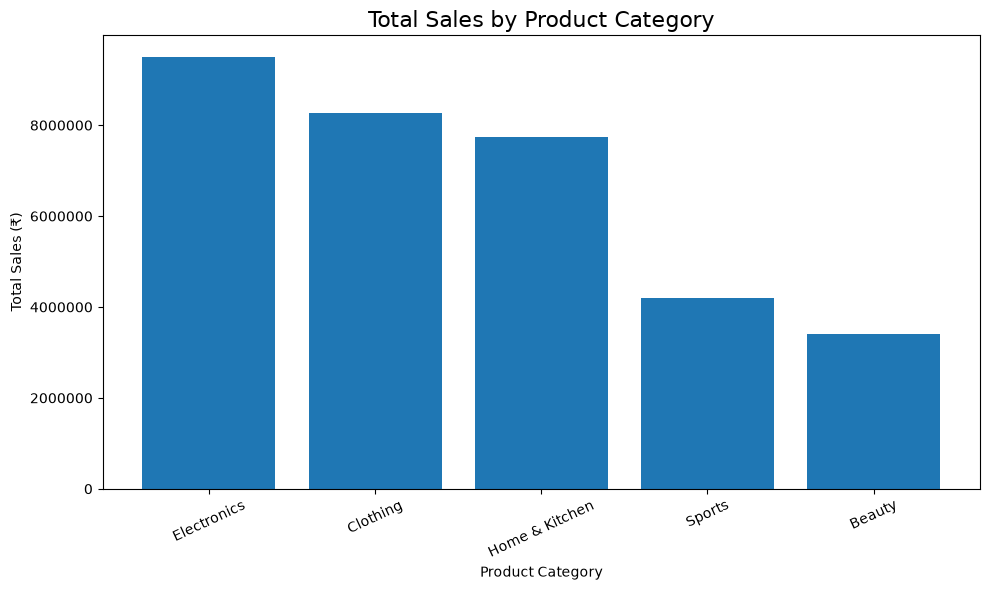

In [20]:

# Sales by Category — Executive Chart

category_chart = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    category_chart["Category"],
    category_chart["Total_Sales"]
)

plt.title("Total Sales by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=25)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


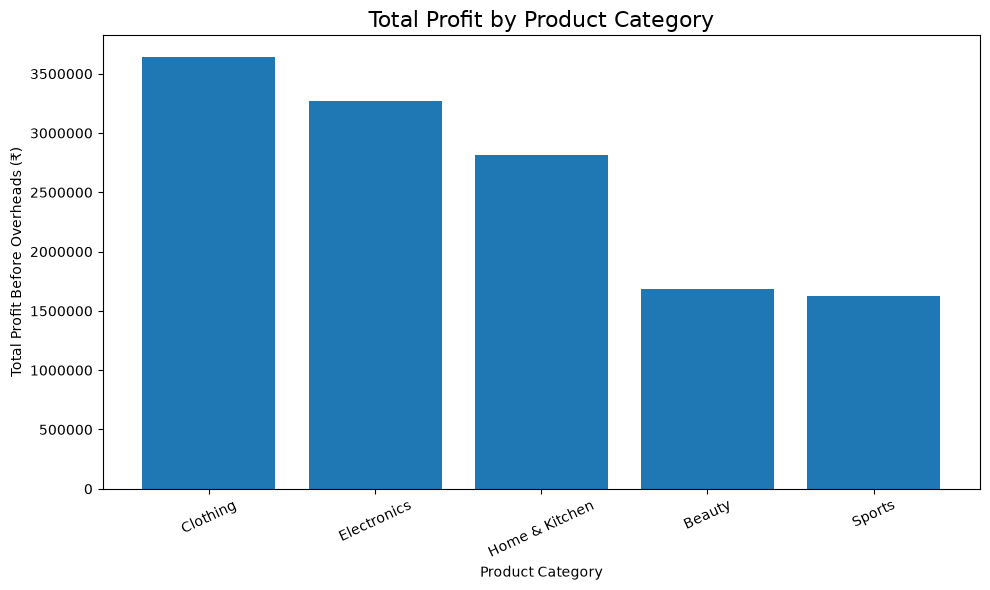

In [21]:

# Profit by Category — Executive Chart

profit_chart = category_analysis.sort_values(
    "Total_Profit", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    profit_chart["Category"],
    profit_chart["Total_Profit"]
)

plt.title("Total Profit by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Profit Before Overheads (₹)")
plt.xticks(rotation=25)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


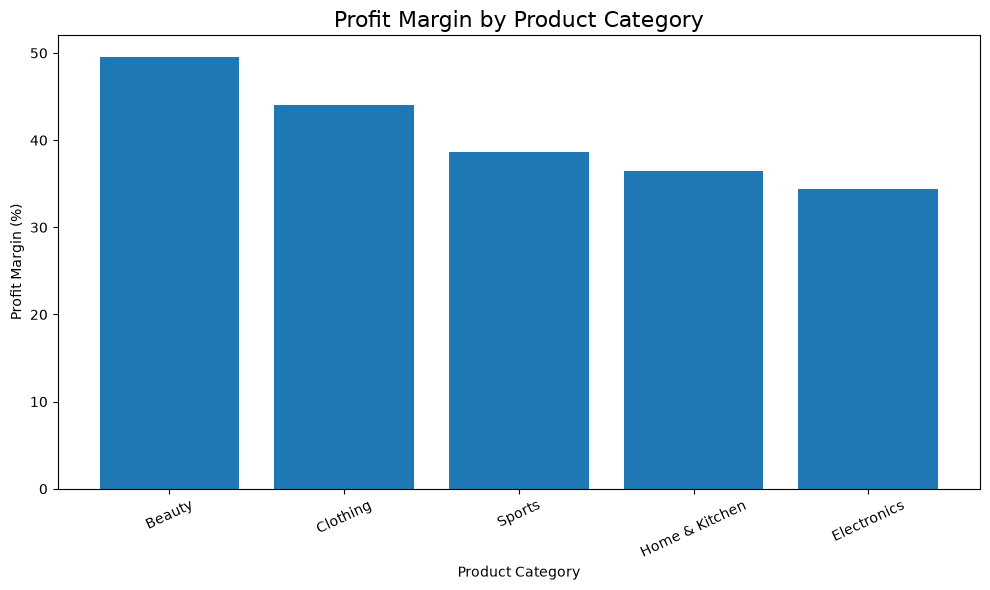

In [22]:

# Profit Margin by Category — Executive Chart

margin_chart = category_analysis.sort_values(
    "Profit_Margin_%", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    margin_chart["Category"],
    margin_chart["Profit_Margin_%"]
)

plt.title("Profit Margin by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


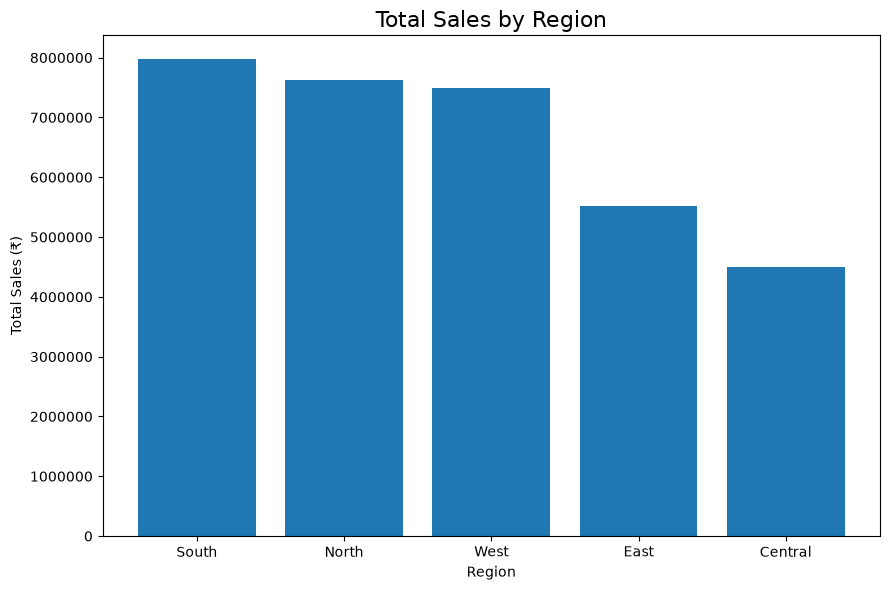

In [23]:

# Sales by Region — Executive Chart

region_chart = region_analysis.sort_values(
    "Total_Sales", ascending=False
)

plt.figure(figsize=(9, 6))
plt.bar(
    region_chart["Region"],
    region_chart["Total_Sales"]
)

plt.title("Total Sales by Region", fontsize=16)
plt.xlabel("Region")
plt.ylabel("Total Sales (₹)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


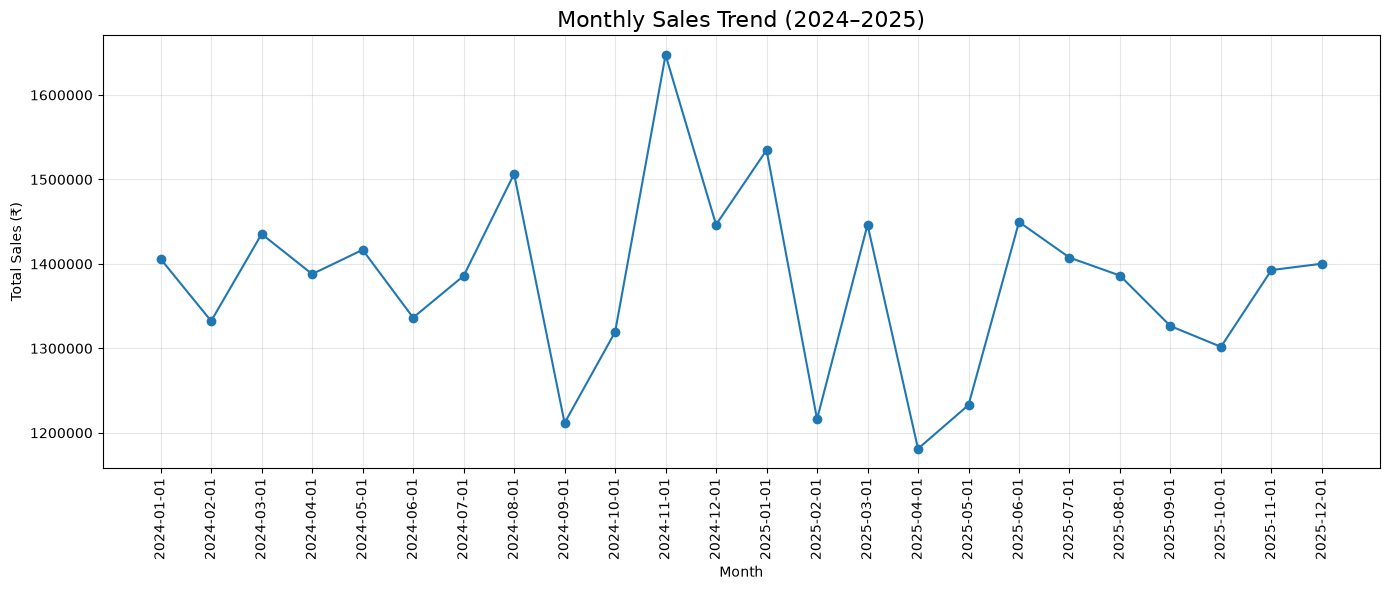

In [24]:

# Monthly Sales Trend — Executive Chart

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Month"].astype(str),
    monthly_analysis["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2024–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=90)
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


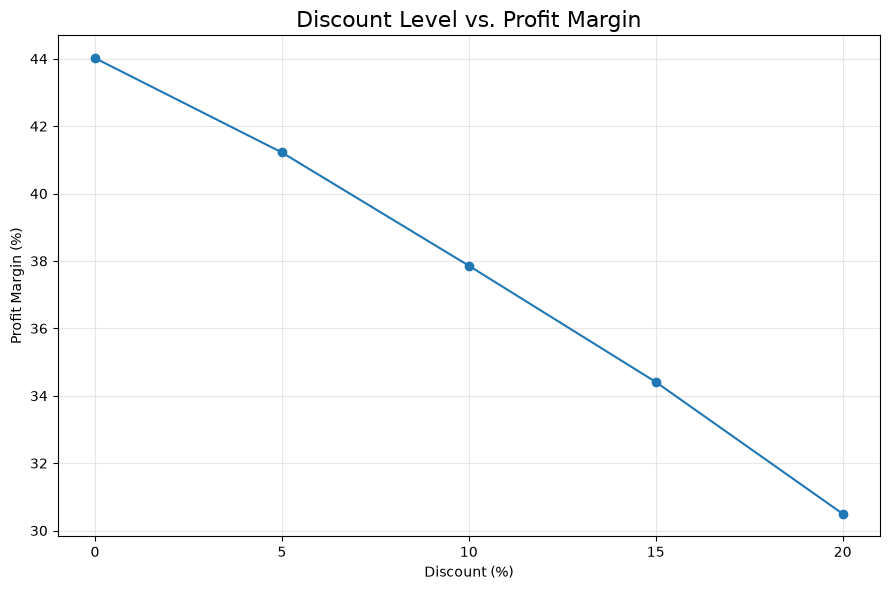

In [25]:

# Discount vs Profit Margin — Executive Chart

discount_chart = discount_analysis.sort_values("Discount_%")

plt.figure(figsize=(9, 6))
plt.plot(
    discount_chart["Discount_%"],
    discount_chart["Profit_Margin_%"],
    marker="o"
)

plt.title("Discount Level vs. Profit Margin", fontsize=16)
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.xticks(discount_chart["Discount_%"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


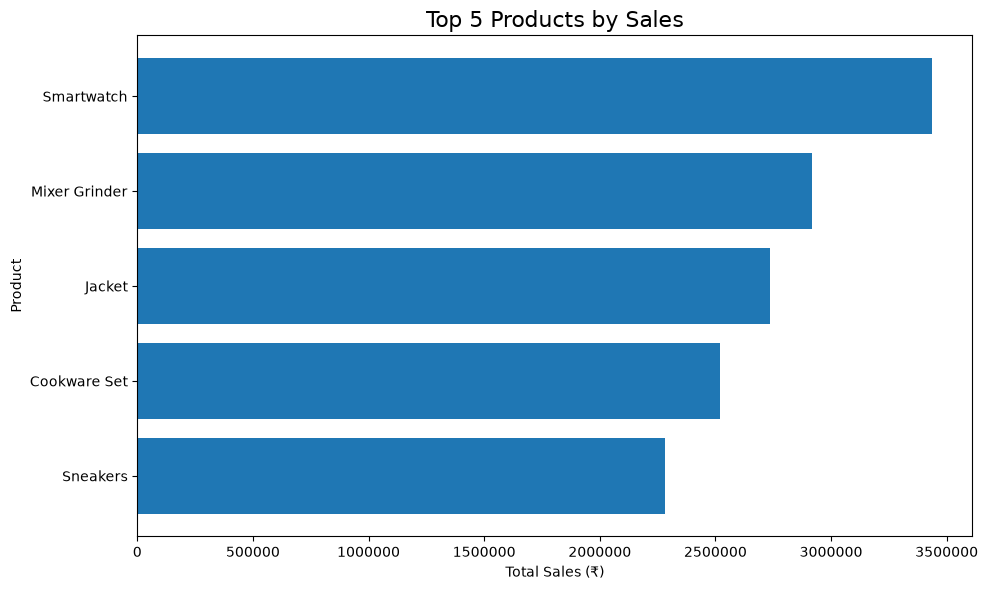

In [26]:

# Top 5 Products by Sales — Executive Chart

top5_products = (
    product_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(5)
    .sort_values("Total_Sales", ascending=True)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top5_products["Product"],
    top5_products["Total_Sales"]
)

plt.title("Top 5 Products by Sales", fontsize=16)
plt.xlabel("Total Sales (₹)")
plt.ylabel("Product")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()


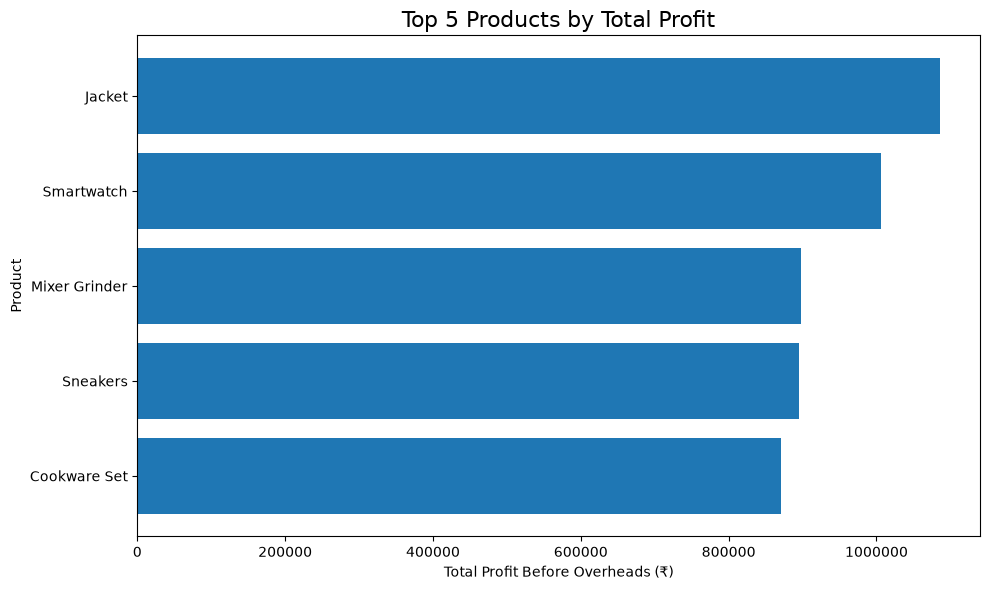

In [27]:

# Top 5 Products by Profit — Executive Chart

top5_profit = (
    product_analysis
    .sort_values("Total_Profit", ascending=False)
    .head(5)
    .sort_values("Total_Profit", ascending=True)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top5_profit["Product"],
    top5_profit["Total_Profit"]
)

plt.title("Top 5 Products by Total Profit", fontsize=16)
plt.xlabel("Total Profit Before Overheads (₹)")
plt.ylabel("Product")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()


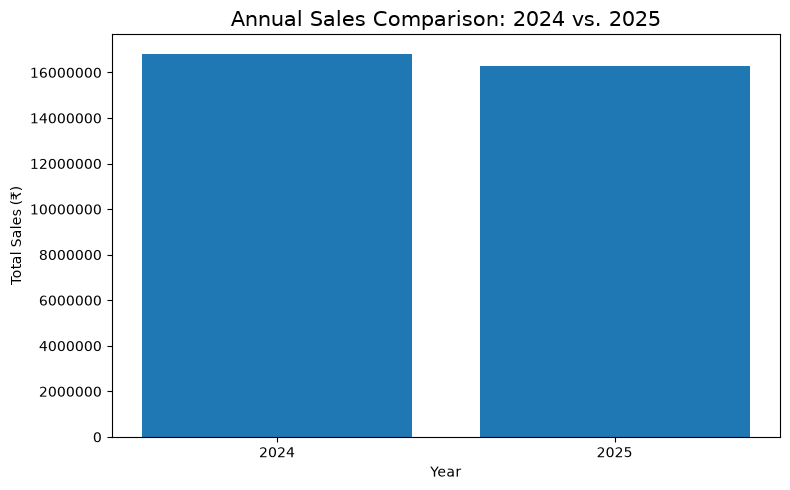

In [28]:

# Annual Sales Comparison — Executive Chart

annual_chart = df.groupby(
    df["Order_Date"].dt.year
)["Sales"].sum()

plt.figure(figsize=(8, 5))
plt.bar(
    annual_chart.index.astype(str),
    annual_chart.values
)

plt.title("Annual Sales Comparison: 2024 vs. 2025", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Total Sales (₹)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


In [29]:

# Executive Findings — Final Summary

findings = pd.DataFrame({
    "Finding": [
        "Overall Business Performance",
        "Category Sales Leader",
        "Category Profit Leader",
        "Category Margin Leader",
        "Regional Sales Leader",
        "Year-over-Year Sales",
        "Discount and Profitability",
        "Top-Selling Product",
        "Top-Profit Product"
    ],
    "Evidence": [
        "₹3.31 crore sales; ₹1.30 crore profit before overheads",
        "Electronics — ₹95.02 lakh sales",
        "Clothing — ₹36.42 lakh profit",
        "Beauty — 49.55% profit margin",
        "South — ₹79.74 lakh sales",
        "Sales declined 3.30% in 2025",
        "Margin falls from 44.02% at 0% discount to 30.50% at 20%",
        "Smartwatch — ₹34.39 lakh sales",
        "Jacket — ₹10.86 lakh profit"
    ],
    "Business Implication": [
        "Establish a baseline for performance monitoring",
        "Protect sales while reviewing product-level profitability",
        "Evaluate opportunities to expand profitable clothing sales",
        "Test targeted growth while monitoring profitability",
        "Study successful regional practices before expansion",
        "Investigate weaker months and test corrective actions",
        "Review discount policies and measure margin impact",
        "Review smartwatch costs, pricing, and discount strategy",
        "Evaluate jacket availability and sales opportunities"
    ]
})

findings


,Finding,Evidence,Business Implication
0,Overall Business Performance,₹3.31 crore sales; ₹1.30 crore profit before o...,Establish a baseline for performance monitoring
1,Category Sales Leader,Electronics — ₹95.02 lakh sales,Protect sales while reviewing product-level pr...
2,Category Profit Leader,Clothing — ₹36.42 lakh profit,Evaluate opportunities to expand profitable cl...
3,Category Margin Leader,Beauty — 49.55% profit margin,Test targeted growth while monitoring profitab...
4,Regional Sales Leader,South — ₹79.74 lakh sales,Study successful regional practices before exp...
5,Year-over-Year Sales,Sales declined 3.30% in 2025,Investigate weaker months and test corrective ...
6,Discount and Profitability,Margin falls from 44.02% at 0% discount to 30....,Review discount policies and measure margin im...
7,Top-Selling Product,Smartwatch — ₹34.39 lakh sales,"Review smartwatch costs, pricing, and discount..."
8,Top-Profit Product,Jacket — ₹10.86 lakh profit,Evaluate jacket availability and sales opportu...


In [30]:

# Strategic Recommendations and ROI Projections

recommendations = pd.DataFrame({
    "Recommendation": [
        "Improve Smartwatch Profitability",
        "Expand High-Margin Beauty Sales",
        "Strengthen Sales Performance Monitoring"
    ],
    "Evidence": [
        "Smartwatch sales ₹34.39 lakh; margin 29.25%",
        "Beauty category margin 49.55%, but lowest category sales",
        "2025 sales declined 3.30%; November sales declined 15.46% year over year"
    ],
    "Proposed Action": [
        "Review supplier costs, pricing, and discount levels",
        "Pilot targeted promotions and product bundles",
        "Monitor monthly sales, orders, profit margins, and campaign results"
    ],
    "Estimated Investment (₹)": [
        25000,
        75000,
        50000
    ],
    "Success Metric": [
        "Improve margin without materially reducing sales volume",
        "Increase sales while maintaining a healthy margin",
        "Identify declines earlier and improve sales performance"
    ]
})

recommendations


,Recommendation,Evidence,Proposed Action,Estimated Investment (₹),Success Metric
0,Improve Smartwatch Profitability,Smartwatch sales ₹34.39 lakh; margin 29.25%,"Review supplier costs, pricing, and discount l...",25000,Improve margin without materially reducing sal...
1,Expand High-Margin Beauty Sales,"Beauty category margin 49.55%, but lowest cate...",Pilot targeted promotions and product bundles,75000,Increase sales while maintaining a healthy margin
2,Strengthen Sales Performance Monitoring,2025 sales declined 3.30%; November sales decl...,"Monitor monthly sales, orders, profit margins,...",50000,Identify declines earlier and improve sales pe...


In [31]:

# ROI Projections — Illustrative Scenarios

roi_data = pd.DataFrame({
    "Recommendation": [
        "Improve Smartwatch Profitability",
        "Expand High-Margin Beauty Sales"
    ],
    "Estimated_Investment": [
        25000,
        75000
    ],
    "Projected_Profit_Uplift": [
        68772.80,
        168834.07
    ]
})

roi_data["Net_Benefit"] = (
    roi_data["Projected_Profit_Uplift"]
    - roi_data["Estimated_Investment"]
)

roi_data["ROI_%"] = (
    roi_data["Net_Benefit"]
    / roi_data["Estimated_Investment"]
    * 100
).round(2)

roi_data


,Recommendation,Estimated_Investment,Projected_Profit_Uplift,Net_Benefit,ROI_%
0,Improve Smartwatch Profitability,25000,68772.80,43772.80,175.09
1,Expand High-Margin Beauty Sales,75000,168834.07,93834.07,125.11


In [32]:

# 90-Day Implementation Timeline

timeline = pd.DataFrame({
    "Phase": [
        "Days 1–30",
        "Days 31–60",
        "Days 61–90"
    ],
    "Priority": [
        "Diagnose and plan",
        "Pilot improvements",
        "Evaluate and scale"
    ],
    "Key Activities": [
        "Review smartwatch costs, pricing, discount data, and monthly sales trends",
        "Test Beauty promotions and smartwatch pricing or supplier improvements",
        "Compare results with baseline KPIs and decide which actions to expand"
    ],
    "Success Measures": [
        "Baseline KPIs documented and pilot plan approved",
        "Pilot sales, margins, and spending tracked",
        "ROI reviewed; scale, revise, or stop each pilot"
    ]
})

timeline


,Phase,Priority,Key Activities,Success Measures
0,Days 1–30,Diagnose and plan,"Review smartwatch costs, pricing, discount dat...",Baseline KPIs documented and pilot plan approved
1,Days 31–60,Pilot improvements,Test Beauty promotions and smartwatch pricing ...,"Pilot sales, margins, and spending tracked"
2,Days 61–90,Evaluate and scale,Compare results with baseline KPIs and decide ...,"ROI reviewed; scale, revise, or stop each pilot"
